## 1. Setup & konfigurasi

In [1]:
import sys, glob, os, time, warnings
sys.path.insert(0, "/opt/spark/python")
sys.path.insert(0, glob.glob("/opt/spark/python/lib/py4j*.zip")[0])


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pyspark import StorageLevel
from pyspark.sql import SparkSession, Window, functions as F

# Keperluan Spark MLlib
from pyspark.ml import Pipeline
from pyspark.ml.feature import Imputer, StringIndexer, OneHotEncoder, VectorAssembler, StandardScaler
from pyspark.ml.classification import LogisticRegression, RandomForestClassifier, GBTClassifier

# Keperluan Scikit-Learn
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline as SkPipeline
from sklearn.preprocessing import StandardScaler as SkScaler, OneHotEncoder as SkOneHot
from sklearn.linear_model import LogisticRegression as SkLogReg
from sklearn.ensemble import HistGradientBoostingClassifier

### Spark

In [3]:
spark = (SparkSession.builder
    .appName("Helpfulness - Machine Learning")
    .master("local[4]")
    .config("spark.driver.memory", "5g")
    .config("spark.driver.maxResultSize", "1g")
    .config("spark.sql.shuffle.partitions", "16")
    .config("spark.hadoop.dfs.replication", "1")
    .getOrCreate())

# Biar kalau ada warning atau yang lain tidak keluar cuman kalau error aja 
spark.sparkContext.setLogLevel("ERROR")
warnings.filterwarnings('ignore')

# HDFS path 
HDFS = "hdfs://namenode:9000"

spark

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/11/06 09:55:40 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


In [7]:
SOURCE_PATH   = f"{HDFS}/data/amazon_reviews/final_reviews_parquet"
FEATURES_PATH = f"{HDFS}/data/ml/helpfulness_features"
MODEL_DIR     = f"{HDFS}/data/ml/models"
OUT_DIR       = "outputs"; os.makedirs(OUT_DIR, exist_ok=True)

CUTOFF            = "2016-12-31"   # review setelah tanggal ini = belum matang (tidak dipakai sbg label)
SEED              = 42 
SMALL_N           = 200000         # ukuran train untuk perbandingan Spark vs scikit-learn 
REBUILD_FEATURES  = False           # Ini cuman buat kalau pertama kali True (soalnya belum ada)
                                   # kalau udah ada atau pernah run pake False
DEV_FRACTION      = 1.0            # 0.05 untuk dry-run cepat; 1.0 untuk run final

### Read dari final reviews (hasil ETL sebelumnya)

In [6]:
raw = spark.read.parquet(SOURCE_PATH)

raw.printSchema()

[Stage 0:>                                                          (0 + 1) / 1]

root
 |-- asin: string (nullable = true)
 |-- overall: double (nullable = true)
 |-- reviewText: string (nullable = true)
 |-- reviewerID: string (nullable = true)
 |-- summary: string (nullable = true)
 |-- verified: boolean (nullable = true)
 |-- vote: integer (nullable = true)
 |-- review_datetime: string (nullable = true)
 |-- also_buy: array (nullable = true)
 |    |-- element: string (containsNull = true)
 |-- also_view: array (nullable = true)
 |    |-- element: string (containsNull = true)
 |-- brand: string (nullable = true)
 |-- category: array (nullable = true)
 |    |-- element: string (containsNull = true)
 |-- description: array (nullable = true)
 |    |-- element: string (containsNull = true)
 |-- details: struct (nullable = true)
 |    |-- \n    Item Weight: \n    : string (nullable = true)
 |    |-- \n    Package Dimensions: \n    : string (nullable = true)
 |    |-- \n    Product Dimensions: \n    : string (nullable = true)
 |    |--  Date first listed on Amazon:: str

In [6]:
columns = ["reviewerID", "asin", "overall", "verified", "vote", 
           "reviewText", "summary", "review_datetime", "brand",
           "main_cat", "price_clean"]
# Ambil yang perlu aja
reviews = raw.select(*columns)

n_reviews_raw = reviews.count()
print(f"Jumlah review di clean layer: ", n_reviews_raw)
reviews.printSchema()

Jumlah review di clean layer:  2488912
root
 |-- reviewerID: string (nullable = true)
 |-- asin: string (nullable = true)
 |-- overall: double (nullable = true)
 |-- verified: boolean (nullable = true)
 |-- vote: integer (nullable = true)
 |-- reviewText: string (nullable = true)
 |-- summary: string (nullable = true)
 |-- review_datetime: string (nullable = true)
 |-- brand: string (nullable = true)
 |-- main_cat: string (nullable = true)
 |-- price_clean: double (nullable = true)



udah sesuai sama jumlah final review (2.488.912)

### Pembersihan Akhir

In [8]:
reviews = reviews.dropDuplicates(["reviewerID", "asin", "review_datetime", "reviewText", "summary", "overall"])
n_reviews_clean = reviews.count()
print(f"Setelah dedup: {n_reviews_clean:,}  (dibuang {n_reviews_raw - n_reviews_clean:,})")

[Stage 12:==========================================>             (12 + 4) / 16]

Setelah dedup: 2,488,658  (dibuang 254)


In [9]:
top30_counts = (
    reviews.groupBy("brand")
           .count()
           .orderBy(F.desc("count"))
)

top30_counts.show(30, truncate=False)

[Stage 18:==========================================>             (12 + 4) / 16]

+----------------------+------+
|brand                 |count |
+----------------------+------+
|Nintendo              |215383|
|Electronic Arts       |180428|
|Microsoft             |162004|
|Sony                  |150379|
|Activision            |109284|
|Ubisoft               |108679|
|Logitech              |47921 |
|Square Enix           |46361 |
|WB Games              |42044 |
|2K                    |38264 |
|Razer                 |36762 |
|Sega                  |34725 |
|Capcom                |34220 |
|Bethesda              |34067 |
|Turtle Beach          |30861 |
|Konami                |26638 |
|Unknown               |26585 |
|Rockstar Games        |24660 |
|PDP                   |22905 |
|THQ                   |22789 |
|Blizzard Entertainment|20897 |
|Atari                 |20818 |
|Nyko                  |20508 |
|Bandai                |19445 |
|LucasArts             |17452 |
|Mad Catz              |17256 |
|Redragon              |15843 |
|Corsair               |15672 |
|Generic

### Disini Brand hanya diambil yang top 30 kalau diluar itu Other

In [10]:
# 30 brand teratas (berdasarkan jumlah review); sisanya digabung menjadi 'Other'
top_brands = [r["brand"] for r in reviews.groupBy("brand").count().orderBy(F.desc("count")).limit(30).collect()]
print("Brand teratas:", top_brands[:8], "...")

[Stage 24:==========================================>             (12 + 4) / 16]

Brand teratas: ['Nintendo', 'Electronic Arts', 'Microsoft', 'Sony', 'Activision', 'Ubisoft', 'Logitech', 'Square Enix'] ...


In [11]:
def count_matches(text_col, regex):
    # jumlah karakter yang cocok dengan regex
    return F.length(text_col) - F.length(F.regexp_replace(text_col, regex, ""))

def add_basic_features(df):
    # Label, tanggal, dan fitur dari isi review (tidak butuh konteks produk/user)
    text = F.coalesce(F.col("reviewText"), F.lit(""))
    summary = F.coalesce(F.col("summary"), F.lit(""))
    n_chars = F.length(text)
    is_empty = F.length(F.trim(text)) == 0

    return (df
        .withColumn("label", (F.col("vote") > 0).cast("int"))
        .withColumn("tgl", F.to_date("review_datetime"))
        .withColumn("day", F.datediff(F.col("tgl"), F.lit("1970-01-01").cast("date")))
        .withColumn("tahun", F.year("tgl"))
        .withColumn("verified", F.col("verified").cast("int"))
        .withColumn("has_price", F.col("price_clean").isNotNull().cast("int"))
        .withColumn("brand", F.when(F.col("brand").isin(top_brands), F.col("brand")).otherwise("Other"))
        .withColumn("text_len", n_chars)
        .withColumn("word_count", F.when(is_empty, 0).otherwise(F.size(F.split(F.trim(text), r"\s+"))))
        .withColumn("summary_len", F.length(summary))
        .withColumn("n_exclaim", count_matches(text, "!"))
        .withColumn("n_question", count_matches(text, r"\?"))
        .withColumn("n_sentences", F.when(is_empty, 0).otherwise(F.size(F.split(F.trim(text), r"[.!?]+"))))
        .withColumn("has_url", text.rlike(r"(?i)http|www\.").cast("int"))
        .withColumn("has_linebreak", text.contains("\n").cast("int"))
        .withColumn("upper_ratio", F.when(n_chars > 0, count_matches(text, "[A-Z]") / n_chars).otherwise(0.0))
        .withColumn("digit_ratio", F.when(n_chars > 0, count_matches(text, "[0-9]") / n_chars).otherwise(0.0))
        .withColumn("avg_word_len", F.when(F.col("word_count") > 0, F.col("text_len") / F.col("word_count")).otherwise(0.0))
        .drop("reviewText", "summary", "review_datetime"))


def add_history_features(df):
    # Fitur riwayat user dan produk: window yang hanya melihat HARI SEBELUMNYA (rangeBetween ... -1)
    user_past = Window.partitionBy("reviewerID").orderBy("day").rangeBetween(Window.unboundedPreceding, -1)
    prod_past = Window.partitionBy("asin").orderBy("day").rangeBetween(Window.unboundedPreceding, -1)
    prod_all  = Window.partitionBy("asin")

    return (df
        .withColumn("user_prev_n",    F.count("label").over(user_past))
        .withColumn("user_prev_help", F.avg("label").over(user_past))        # null = belum punya riwayat
        .withColumn("prod_prev_n",    F.count("label").over(prod_past))      # posisi review dalam produk
        .withColumn("prod_prev_avg",  F.avg("overall").over(prod_past))      # null = review pertama produk
        .withColumn("prod_gap_days",  F.col("day") - F.min("day").over(prod_all))
        .withColumn("rating_dev_past",     F.col("overall") - F.col("prod_prev_avg"))
        .withColumn("abs_rating_dev_past", F.abs("rating_dev_past")))


MISSING_FILL = {"brand": "Other", "main_cat": "Unknown", "user_prev_help": -1.0,
                "prod_prev_avg": -1.0, "rating_dev_past": 0.0, "abs_rating_dev_past": 0.0}

In [12]:
def add_split(df):
    bucket = F.pmod(F.hash("reviewerID"), F.lit(20))
    return df.withColumn("split",
        F.when(F.col("tgl") > F.lit(CUTOFF).cast("date"), "infer")
         .when(bucket < 14, "train")
         .when(bucket < 17, "val")
         .otherwise("test"))


FEATURE_COLUMNS = [
    "overall", "verified", "text_len", "word_count", "has_price", "price_clean", "brand", "main_cat",
    "summary_len", "n_exclaim", "n_question", "n_sentences", "has_url", "has_linebreak",
    "upper_ratio", "digit_ratio", "avg_word_len",
    "user_prev_n", "user_prev_help", "prod_prev_avg", "rating_dev_past", "abs_rating_dev_past",
    "tahun", "prod_prev_n", "prod_gap_days"]

if REBUILD_FEATURES:
    t0 = time.time()
    features = (reviews
        .transform(add_basic_features)
        .transform(add_history_features)
        .fillna(MISSING_FILL)
        .transform(add_split)
        .select("reviewerID", "asin", "tgl", "split", "label", *FEATURE_COLUMNS))
    features.write.mode("overwrite").parquet(FEATURES_PATH)
    print(f"Tabel fitur tersimpan ({time.time() - t0:.0f} detik): {FEATURES_PATH}")

data = spark.read.parquet(FEATURES_PATH)
if DEV_FRACTION < 1.0:
    data = data.sample(False, DEV_FRACTION, SEED)

Tabel fitur tersimpan (68 detik): hdfs://namenode:9000/data/ml/helpfulness_features


In [8]:
data = spark.read.parquet(FEATURES_PATH)
if DEV_FRACTION < 1.0:
    data = data.sample(False, DEV_FRACTION, SEED)

 tahun  n_ulasan  rasio_helpful
  2000      9949          0.652
  2001     23049          0.491
  2002     28470          0.442
  2003     25539          0.477
  2004     24913          0.599
  2005     25483          0.674
  2006     24522          0.671
  2007     43100          0.489
  2008     56133          0.415
  2009     69570          0.356
  2010     68101          0.339
  2011     83694          0.298
  2012    117090          0.241
  2013    235932          0.153
  2014    340343          0.119
  2015    457075          0.092
  2016    447324          0.102
  2017    281464          0.066
  2018    125963          0.022


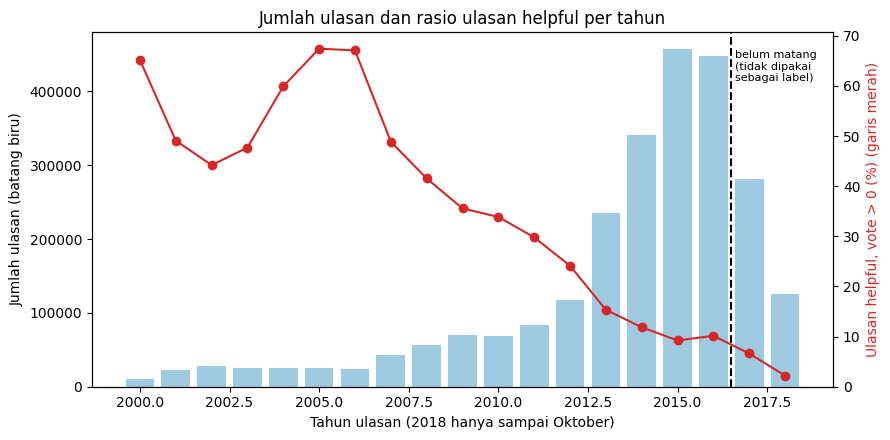

In [9]:
MIN_REVIEWS = 1000   # tahun dengan ulasan lebih sedikit disembunyikan (persentasenya tidak stabil)

yearly = (data.groupBy(F.year("tgl").alias("tahun"))
              .agg(F.count("*").alias("n_ulasan"), F.avg("label").alias("rasio_helpful"))
              .orderBy("tahun").toPandas())
yearly = yearly[yearly["n_ulasan"] >= MIN_REVIEWS]
print(yearly.round(3).to_string(index=False))

cutoff_year = int(CUTOFF[:4])
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.bar(yearly["tahun"], yearly["n_ulasan"], color="#9ecae1")
ax.set_xlabel("Tahun ulasan (2018 hanya sampai Oktober)")
ax.set_ylabel("Jumlah ulasan (batang biru)")

ax2 = ax.twinx()
ax2.plot(yearly["tahun"], yearly["rasio_helpful"] * 100, "o-", color="#d62728")
ax2.set_ylabel("Ulasan helpful, vote > 0 (%) (garis merah)", color="#d62728")
ax2.set_ylim(bottom=0)

ax.axvline(cutoff_year + 0.5, color="k", ls="--")
ax.text(cutoff_year + 0.6, ax.get_ylim()[1] * 0.95, "belum matang\n(tidak dipakai\nsebagai label)", fontsize=8, va="top")
ax.set_title("Jumlah ulasan dan rasio ulasan helpful per tahun")
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/fig_helpful_per_tahun.png", dpi=150)
plt.show()

In [13]:
(data.groupBy("split")
     .agg(F.count("*").alias("baris"), F.round(F.avg("label"), 4).alias("rasio_helpful"),
          F.min("tgl").alias("dari"), F.max("tgl").alias("sampai"))
     .orderBy("split").show(truncate=False))

print("Rasio helpful per kuartal (review baru belum sempat divote):")
(data.filter("tgl >= '2015-01-01'")
     .groupBy(F.year("tgl").alias("tahun"), F.quarter("tgl").alias("kuartal"))
     .agg(F.count("*").alias("n"), F.round(F.avg("label"), 3).alias("rasio_helpful"))
     .orderBy("tahun", "kuartal").show(20))

+-----+-------+-------------+----------+----------+
|split|baris  |rasio_helpful|dari      |sampai    |
+-----+-------+-------------+----------+----------+
|infer|407427 |0.0526       |2017-01-01|2018-10-02|
|test |315073 |0.1944       |1999-09-12|2016-12-31|
|train|1454487|0.1926       |1997-11-29|2016-12-31|
|val  |311671 |0.1931       |1997-11-08|2016-12-31|
+-----+-------+-------------+----------+----------+

Rasio helpful per kuartal (review baru belum sempat divote):
+-----+-------+------+-------------+
|tahun|kuartal|     n|rasio_helpful|
+-----+-------+------+-------------+
| 2015|      1|143651|        0.073|
| 2015|      2| 98102|        0.085|
| 2015|      3|103345|        0.084|
| 2015|      4|111977|        0.131|
| 2016|      1|138314|        0.096|
| 2016|      2|103959|        0.106|
| 2016|      3|101544|        0.103|
| 2016|      4|103507|        0.102|
| 2017|      1|105761|        0.076|
| 2017|      2| 65957|        0.076|
| 2017|      3| 58008|        0.047|
| 20

In [14]:
split_df = {s: data.filter(F.col("split") == s) for s in ["train", "val", "test"]}

n_train = split_df["train"].count()
n_pos = split_df["train"].filter("label = 1").count()
W_POS = (n_train - n_pos) / n_pos      # bobot kelas helpful; kelas lain = 1

def add_weight(d):
    return d.withColumn("w", F.when(F.col("label") == 1, F.lit(W_POS)).otherwise(F.lit(1.0)))

train, val, test = [add_weight(split_df[s]).persist(StorageLevel.MEMORY_AND_DISK) for s in ["train", "val", "test"]]
n_val, n_test = val.count(), test.count()
print(f"train={n_train:,}  val={n_val:,}  test={n_test:,}  | helpful(train)={n_pos/n_train:.3%}  | bobot kelas={W_POS:.2f}")

# Subset train untuk perbandingan Spark vs scikit-learn (baris identik di kedua engine)
train_small = train.sample(False, min(1.0, SMALL_N / n_train), SEED).persist(StorageLevel.MEMORY_AND_DISK)
n_small = train_small.count()
print(f"train_small={n_small:,}")

train=1,454,487  val=311,671  test=315,073  | helpful(train)=19.255%  | bobot kelas=4.19


[Stage 59:==============================================>           (4 + 1) / 5]

train_small=199,767


In [15]:
STATIK   = ["overall", "verified", "text_len", "word_count", "has_price"]
TEKS     = ["summary_len", "n_exclaim", "n_question", "n_sentences", "has_url",
            "has_linebreak", "upper_ratio", "digit_ratio", "avg_word_len"]
RIWAYAT  = ["user_prev_n", "user_prev_help"]
DEVIASI  = ["prod_prev_avg", "rating_dev_past", "abs_rating_dev_past"]
EKSPOSUR = ["tahun", "prod_prev_n", "prod_gap_days"]

SCENARIOS = {
    "A": STATIK + TEKS + RIWAYAT + DEVIASI + EKSPOSUR,   # dengan eksposur
    "B": STATIK + TEKS + RIWAYAT + DEVIASI,              # tanpa eksposur
}
CATEGORICAL = ["brand", "main_cat"]
for name, feats in SCENARIOS.items():
    print(f"Skenario {name}: {len(feats)} fitur numerik + price_clean + {CATEGORICAL}")

Skenario A: 22 fitur numerik + price_clean + ['brand', 'main_cat']
Skenario B: 19 fitur numerik + price_clean + ['brand', 'main_cat']


In [16]:
from pyspark.ml.functions import vector_to_array
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             average_precision_score, roc_auc_score, precision_recall_curve,
                             confusion_matrix)

RESULTS, PREDICTIONS, MODELS = [], {}, {}


def collect_probabilities(model, df):
    # label + probabilitas kelas helpful sebagai pandas (hanya 2 kolom, ringan)
    return model.transform(df).select("label", vector_to_array("probability")[1].alias("p")).toPandas()


def best_threshold(y, p):
    precision, recall, thresholds = precision_recall_curve(y, p)
    f1 = 2 * precision[:-1] * recall[:-1] / (precision[:-1] + recall[:-1] + 1e-12)
    return float(thresholds[int(np.argmax(f1))])


def score(y, p, threshold):
    y_hat = (p >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, y_hat).ravel()
    return {"accuracy": accuracy_score(y, y_hat), "precision": precision_score(y, y_hat, zero_division=0),
            "recall": recall_score(y, y_hat), "f1": f1_score(y, y_hat),
            "pr_auc": average_precision_score(y, p), "roc_auc": roc_auc_score(y, p),
            "threshold": threshold, "TP": tp, "FP": fp, "FN": fn, "TN": tn}


def register(scenario, algo, engine, n_rows, fit_seconds, pred_val, pred_test):
    threshold = best_threshold(pred_val["label"].values, pred_val["p"].values)
    row = score(pred_test["label"].values, pred_test["p"].values, threshold)
    row.update(skenario=scenario, model=algo, engine=engine, train_rows=n_rows,
               fit_seconds=round(fit_seconds, 1),
               val_pr_auc=average_precision_score(pred_val["label"], pred_val["p"]))
    RESULTS.append(row)
    PREDICTIONS[(scenario, algo, engine, n_rows)] = (pred_val, pred_test, threshold)
    print(f"[{scenario}] {algo:4s} {engine:12s} n={n_rows:>9,} | acc={row['accuracy']:.3f} P={row['precision']:.3f} "
          f"R={row['recall']:.3f} F1={row['f1']:.3f} PR-AUC={row['pr_auc']:.3f} ROC-AUC={row['roc_auc']:.3f} | {fit_seconds:.0f}s")

In [17]:
def build_pipeline(features, algo, reg_param=1e-3):
    stages = [
        Imputer(strategy="median", inputCols=["price_clean"], outputCols=["price_imp"]),
        StringIndexer(inputCols=CATEGORICAL, outputCols=["brand_idx", "main_cat_idx"], handleInvalid="keep"),
    ]
    if algo == "LR":
        stages += [
            OneHotEncoder(inputCols=["brand_idx", "main_cat_idx"], outputCols=["brand_oh", "main_cat_oh"], handleInvalid="keep"),
            VectorAssembler(inputCols=features + ["price_imp"], outputCol="num_raw"),
            StandardScaler(inputCol="num_raw", outputCol="num_scaled", withMean=False, withStd=True),
            VectorAssembler(inputCols=["num_scaled", "brand_oh", "main_cat_oh"], outputCol="features"),
            LogisticRegression(labelCol="label", weightCol="w", maxIter=50, regParam=reg_param,
                               elasticNetParam=0.0, standardization=False),
        ]
    else:
        stages.append(VectorAssembler(inputCols=features + ["price_imp", "brand_idx", "main_cat_idx"], outputCol="features"))
        if algo == "RF":
            stages.append(RandomForestClassifier(labelCol="label", weightCol="w", numTrees=80, maxDepth=8, maxBins=64,
                                                 featureSubsetStrategy="sqrt", subsamplingRate=0.5, seed=SEED))
        elif algo == "GBT":
            stages.append(GBTClassifier(labelCol="label", weightCol="w", maxIter=50, maxDepth=5, maxBins=64, seed=SEED))
    return Pipeline(stages=stages)


def fit_timed(features, algo, train_df, reg_param=1e-3):
    start = time.time()
    model = build_pipeline(features, algo, reg_param).fit(train_df)
    return model, time.time() - start


BEST_REG = {}   # regParam LR terbaik per skenario (dipilih di validasi)

In [18]:
for scenario, features in SCENARIOS.items():
    # --- Logistic Regression: pilih regParam berdasarkan PR-AUC validasi
    candidates = {}
    for reg in [1e-4, 1e-3, 1e-2]:
        model, secs = fit_timed(features, "LR", train, reg)
        pred_val = collect_probabilities(model, val)
        candidates[reg] = (model, secs, pred_val, average_precision_score(pred_val["label"], pred_val["p"]))
    BEST_REG[scenario] = max(candidates, key=lambda r: candidates[r][3])
    print(f"Skenario {scenario}: regParam terbaik = {BEST_REG[scenario]:g} "
          f"(val PR-AUC: { {r: round(c[3], 3) for r, c in candidates.items()} })")

    model, secs, pred_val, _ = candidates[BEST_REG[scenario]]
    MODELS[(scenario, "LR")] = model
    register(scenario, "LR", "Spark MLlib", n_train, secs, pred_val, collect_probabilities(model, test))

    # --- Random Forest dan GBT
    for algo in ["RF", "GBT"]:
        model, secs = fit_timed(features, algo, train)
        MODELS[(scenario, algo)] = model
        register(scenario, algo, "Spark MLlib", n_train, secs,
                 collect_probabilities(model, val), collect_probabilities(model, test))

netlib-blas: JNI_OnLoad: dlopen(libblas.so.3) failed: libblas.so.3: cannot open shared object file: No such file or directory
                                                                                

Skenario A: regParam terbaik = 0.0001 (val PR-AUC: {0.0001: 0.602, 0.001: 0.593, 0.01: 0.578})


[A] LR   Spark MLlib  n=1,454,487 | acc=0.818 P=0.525 R=0.680 F1=0.593 PR-AUC=0.596 ROC-AUC=0.855 | 29s


[A] RF   Spark MLlib  n=1,454,487 | acc=0.832 P=0.555 R=0.696 F1=0.617 PR-AUC=0.651 ROC-AUC=0.879 | 128s


[A] GBT  Spark MLlib  n=1,454,487 | acc=0.843 P=0.578 R=0.700 F1=0.633 PR-AUC=0.683 ROC-AUC=0.888 | 86s


Skenario B: regParam terbaik = 0.0001 (val PR-AUC: {0.0001: 0.557, 0.001: 0.55, 0.01: 0.54})


[B] LR   Spark MLlib  n=1,454,487 | acc=0.804 P=0.497 R=0.643 F1=0.561 PR-AUC=0.547 ROC-AUC=0.830 | 36s


[B] RF   Spark MLlib  n=1,454,487 | acc=0.806 P=0.500 R=0.692 F1=0.581 PR-AUC=0.588 ROC-AUC=0.852 | 149s


[B] GBT  Spark MLlib  n=1,454,487 | acc=0.814 P=0.516 R=0.689 F1=0.590 PR-AUC=0.620 ROC-AUC=0.861 | 84s


In [30]:
ABLATION_USE_SMALL = False     # True = lebih cepat (pakai train_small), tapi selisih kecil jadi kurang akurat
ablation_train = train_small if ABLATION_USE_SMALL else train

ABLATION_GROUPS = {"statik": STATIK, "teks": TEKS, "riwayat": RIWAYAT, "deviasi": DEVIASI, "eksposur": EKSPOSUR}
GROUP_ORDER = ["statik", "teks", "riwayat", "deviasi", "eksposur"]
_ablation_cache = {}


def ablation_score(group_names):
    # latih GBT dengan kelompok fitur tertentu, nilai di validasi (hasil di-cache)
    key = tuple(group_names)
    if key not in _ablation_cache:
        features = sum((ABLATION_GROUPS[g] for g in group_names), [])
        model, secs = fit_timed(features, "GBT", ablation_train)
        pred = collect_probabilities(model, val)
        _ablation_cache[key] = {"n_fitur": len(features),
                                "pr_auc": average_precision_score(pred["label"], pred["p"]),
                                "roc_auc": roc_auc_score(pred["label"], pred["p"]),
                                "detik": round(secs)}
    return _ablation_cache[key]


# 1) Ablation bertahap
rows, previous = [], None
for i in range(1, len(GROUP_ORDER) + 1):
    result = ablation_score(GROUP_ORDER[:i])
    rows.append({"langkah": "statik saja" if i == 1 else f"+ {GROUP_ORDER[i-1]}", **result,
                 "delta_pr_auc": None if previous is None else result["pr_auc"] - previous})
    previous = result["pr_auc"]
stepwise = pd.DataFrame(rows)
print("Ablation bertahap (validasi, GBT):")
print(stepwise.round(4).to_string(index=False))

# 2) Leave-one-group-out dari skenario A
full_a = ablation_score(GROUP_ORDER)
rows = [{"konfigurasi": "A (semua kelompok)", **full_a, "delta_vs_A": 0.0}]
for group in GROUP_ORDER[1:]:
    result = ablation_score([g for g in GROUP_ORDER if g != group])
    rows.append({"konfigurasi": f"A tanpa {group}", **result, "delta_vs_A": result["pr_auc"] - full_a["pr_auc"]})
leave_one_out = pd.DataFrame(rows)
print("\nLeave-one-group-out (validasi, GBT):")
print(leave_one_out.round(4).to_string(index=False))

stepwise.to_csv(f"{OUT_DIR}/ablation_stepwise.csv", index=False)
leave_one_out.to_csv(f"{OUT_DIR}/ablation_leave_one_out.csv", index=False)

Ablation bertahap (validasi, GBT):
    langkah  n_fitur  pr_auc  roc_auc  detik  delta_pr_auc
statik saja        5  0.5652   0.8413     65           NaN
     + teks       14  0.5680   0.8424     71        0.0027
  + riwayat       16  0.5769   0.8443     73        0.0090
  + deviasi       19  0.6161   0.8601     75        0.0392
 + eksposur       22  0.6762   0.8859     77        0.0601



Leave-one-group-out (validasi, GBT):
       konfigurasi  n_fitur  pr_auc  roc_auc  detik  delta_vs_A
A (semua kelompok)       22  0.6762   0.8859     77      0.0000
      A tanpa teks       13  0.6771   0.8859     70      0.0009
   A tanpa riwayat       20  0.6760   0.8858     77     -0.0002
   A tanpa deviasi       19  0.6729   0.8843     73     -0.0033
  A tanpa eksposur       19  0.6161   0.8601     75     -0.0601


In [31]:
# ==========================
# Ablation Skenario B
# Tanpa EKSPOSUR
# ==========================

GROUP_ORDER_B = ["statik", "teks", "riwayat", "deviasi"]
_ablation_cache_B = {}

def ablation_score_B(group_names):
    # latih GBT dengan kelompok fitur tertentu (skenario B)
    key = tuple(group_names)

    if key not in _ablation_cache_B:
        features = sum((ABLATION_GROUPS[g] for g in group_names), [])

        model, secs = fit_timed(features, "GBT", ablation_train)

        pred = collect_probabilities(model, val)

        _ablation_cache_B[key] = {
            "n_fitur": len(features),
            "pr_auc": average_precision_score(pred["label"], pred["p"]),
            "roc_auc": roc_auc_score(pred["label"], pred["p"]),
            "detik": round(secs)
        }

    return _ablation_cache_B[key]
    
rows, previous = [], None
for i in range(1, len(GROUP_ORDER_B) + 1):
    result = ablation_score_B(GROUP_ORDER_B[:i])
    rows.append({
        "langkah": "statik saja" if i == 1 else f"+ {GROUP_ORDER_B[i-1]}",
        **result,
        "delta_pr_auc": None if previous is None else result["pr_auc"] - previous
    })
    previous = result["pr_auc"]

stepwise_B = pd.DataFrame(rows)

print("Ablation bertahap Skenario B (validasi, GBT):")
print(stepwise_B.round(4).to_string(index=False))

full_b = ablation_score_B(GROUP_ORDER_B)

rows = [
    {
        "konfigurasi": "B (tanpa eksposur)",
        **full_b,
        "delta_vs_B": 0.0
    }
]

for group in GROUP_ORDER_B[1:]:
    remaining_groups = [
        g for g in GROUP_ORDER_B 
        if g != group
    ]
    result = ablation_score_B(remaining_groups)
    rows.append({
        "konfigurasi": f"B tanpa {group}",
        **result,
        "delta_vs_B": result["pr_auc"] - full_b["pr_auc"]
    })

leave_one_out_B = pd.DataFrame(rows)

print("\nLeave-one-group-out Skenario B (validasi, GBT):")
print(leave_one_out_B.round(4).to_string(index=False))

stepwise_B.to_csv(
    f"{OUT_DIR}/ablation_stepwise_B.csv",
    index=False
)

leave_one_out_B.to_csv(
    f"{OUT_DIR}/ablation_leave_one_out_B.csv",
    index=False
)

Ablation bertahap Skenario B (validasi, GBT):
    langkah  n_fitur  pr_auc  roc_auc  detik  delta_pr_auc
statik saja        5  0.5652   0.8413     65           NaN
     + teks       14  0.5680   0.8424     68        0.0027
  + riwayat       16  0.5769   0.8443     67        0.0090
  + deviasi       19  0.6161   0.8601     70        0.0392



Leave-one-group-out Skenario B (validasi, GBT):
       konfigurasi  n_fitur  pr_auc  roc_auc  detik  delta_vs_B
B (tanpa eksposur)       19  0.6161   0.8601     70      0.0000
      B tanpa teks       10  0.6162   0.8597     61      0.0001
   B tanpa riwayat       17  0.6109   0.8589     69     -0.0052
   B tanpa deviasi       16  0.5769   0.8443     67     -0.0392


In [21]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline as SkPipeline
from sklearn.preprocessing import StandardScaler as SkScaler, OneHotEncoder as SkOneHot
from sklearn.linear_model import LogisticRegression as SkLogReg
from sklearn.ensemble import HistGradientBoostingClassifier

# Data dibawa ke memori driver sebagai pandas (hanya kolom numerik + kategori, ringan)
all_features = sorted(set(sum(SCENARIOS.values(), [])) | {"price_clean"})
pdf_columns = ["label"] + all_features + CATEGORICAL
train_pd = train_small.select(*pdf_columns).toPandas()
val_pd   = val.select(*pdf_columns).toPandas()
test_pd  = test.select(*pdf_columns).toPandas()

price_median = train_pd["price_clean"].median()
for d in (train_pd, val_pd, test_pd):
    d["price_clean"] = d["price_clean"].fillna(price_median)
sample_weight = np.where(train_pd["label"].values == 1, W_POS, 1.0)
print("pandas:", len(train_pd), len(val_pd), len(test_pd))


def sklearn_model(features, algo, reg_param):
    numeric = features + ["price_clean"]
    if algo == "LR":
        encoder = ColumnTransformer([("num", SkScaler(), numeric),
                                     ("cat", SkOneHot(handle_unknown="ignore", sparse_output=False), CATEGORICAL)])
        estimator = SkLogReg(C=1.0 / (sample_weight.sum() * reg_param), max_iter=300)
    else:
        encoder = ColumnTransformer([("num", "passthrough", numeric),
                                     ("cat", SkOneHot(handle_unknown="ignore", sparse_output=False), CATEGORICAL)])
        estimator = HistGradientBoostingClassifier(max_iter=50, max_depth=5, random_state=SEED)
    return SkPipeline([("x", encoder), ("m", estimator)])


for scenario, features in SCENARIOS.items():
    cols = features + ["price_clean"] + CATEGORICAL
    for algo in ["LR", "GBT"]:
        start = time.time()
        clf = sklearn_model(features, algo, BEST_REG[scenario])
        clf.fit(train_pd[cols], train_pd["label"].values, m__sample_weight=sample_weight)
        secs = time.time() - start
        pred_val  = pd.DataFrame({"label": val_pd["label"].values,  "p": clf.predict_proba(val_pd[cols])[:, 1]})
        pred_test = pd.DataFrame({"label": test_pd["label"].values, "p": clf.predict_proba(test_pd[cols])[:, 1]})
        register(scenario, algo, "scikit-learn", len(train_pd), secs, pred_val, pred_test)

pandas: 199767 311671 315073
[A] LR   scikit-learn n=  199,767 | acc=0.820 P=0.528 R=0.677 F1=0.593 PR-AUC=0.596 ROC-AUC=0.856 | 4s
[A] GBT  scikit-learn n=  199,767 | acc=0.846 P=0.589 R=0.693 F1=0.637 PR-AUC=0.684 ROC-AUC=0.888 | 3s
[B] LR   scikit-learn n=  199,767 | acc=0.807 P=0.502 R=0.636 F1=0.561 PR-AUC=0.547 ROC-AUC=0.831 | 7s
[B] GBT  scikit-learn n=  199,767 | acc=0.819 P=0.528 R=0.669 F1=0.590 PR-AUC=0.616 ROC-AUC=0.859 | 3s


In [22]:
y_test = test_pd["label"].values
prevalence = y_test.mean()
print(f"Prevalensi helpful di test      : {prevalence:.3%}")
print(f"Accuracy kelas mayoritas        : {1 - prevalence:.3%}  (menebak semua 'tidak helpful')")
print(f"PR-AUC acak / ROC-AUC acak      : {prevalence:.3f} / 0.500")
print(f"Baseline skor = panjang teks    : PR-AUC={average_precision_score(y_test, test_pd['text_len']):.3f}  "
      f"ROC-AUC={roc_auc_score(y_test, test_pd['text_len']):.3f}")

results = pd.DataFrame(RESULTS)
columns = ["skenario", "model", "engine", "train_rows", "fit_seconds",
           "accuracy", "precision", "recall", "f1", "pr_auc", "roc_auc", "threshold"]
table = results[columns].sort_values(["skenario", "engine", "pr_auc"], ascending=[True, True, False])
print()
print(table.round(3).to_string(index=False))
table.to_csv(f"{OUT_DIR}/helpfulness_results.csv", index=False)

Prevalensi helpful di test      : 19.436%
Accuracy kelas mayoritas        : 80.564%  (menebak semua 'tidak helpful')
PR-AUC acak / ROC-AUC acak      : 0.194 / 0.500
Baseline skor = panjang teks    : PR-AUC=0.490  ROC-AUC=0.803

skenario model       engine  train_rows  fit_seconds  accuracy  precision  recall    f1  pr_auc  roc_auc  threshold
       A   GBT  Spark MLlib     1454487         86.3     0.843      0.578   0.700 0.633   0.683    0.888      0.686
       A   GBT  Spark MLlib      199767         30.1     0.840      0.573   0.704 0.632   0.677    0.886      0.677
       A    RF  Spark MLlib     1454487        127.7     0.832      0.555   0.696 0.617   0.651    0.879      0.654
       A    LR  Spark MLlib     1454487         29.3     0.818      0.525   0.680 0.593   0.596    0.855      0.602
       A    LR  Spark MLlib      199767         11.1     0.818      0.524   0.685 0.594   0.596    0.856      0.592
       A   GBT scikit-learn      199767          2.8     0.846      0.589   

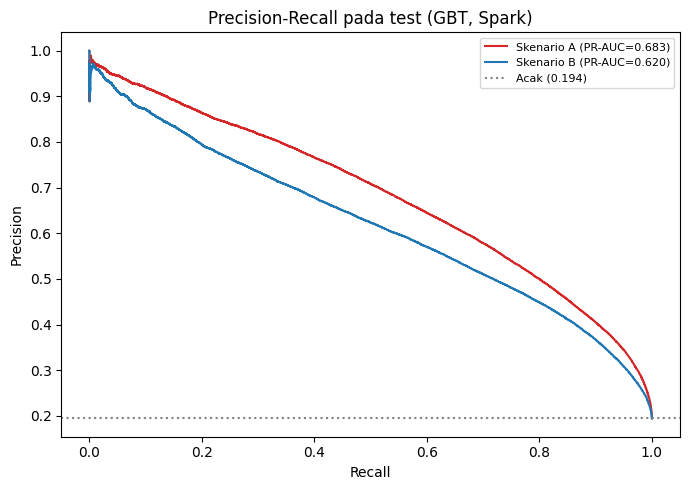

In [23]:
# Kurva Precision-Recall (test): GBT Spark penuh, skenario A vs B
fig, ax = plt.subplots(figsize=(7, 5))
for scenario, color in zip(SCENARIOS, ["#d62728", "#1f77b4"]):
    _, pred_test, _ = PREDICTIONS[(scenario, "GBT", "Spark MLlib", n_train)]
    precision, recall, _ = precision_recall_curve(pred_test["label"], pred_test["p"])
    ap = average_precision_score(pred_test["label"], pred_test["p"])
    ax.plot(recall, precision, color=color, label=f"Skenario {scenario} (PR-AUC={ap:.3f})")
ax.axhline(prevalence, color="gray", ls=":", label=f"Acak ({prevalence:.3f})")
ax.set_xlabel("Recall"); ax.set_ylabel("Precision"); ax.set_title("Precision-Recall pada test (GBT, Spark)")
ax.legend(fontsize=8); plt.tight_layout(); plt.savefig(f"{OUT_DIR}/fig_pr_curve.png", dpi=150); plt.show()

In [24]:
# Dampak ambang klasifikasi pada GBT Spark (test): trade-off precision vs recall
for scenario in SCENARIOS:
    _, pred_test, chosen = PREDICTIONS[(scenario, "GBT", "Spark MLlib", n_train)]
    print(f"\nSkenario {scenario} (ambang terpilih dari validasi = {chosen:.2f})")
    print("ambang | precision | recall | F1")
    for th in [0.3, 0.4, 0.5, 0.6, 0.7, 0.8]:
        y_hat = (pred_test["p"] >= th).astype(int)
        print(f"{th:.1f}    | {precision_score(pred_test['label'], y_hat, zero_division=0):.3f}     | "
              f"{recall_score(pred_test['label'], y_hat):.3f}  | {f1_score(pred_test['label'], y_hat):.3f}")

# Fitur penting GBT
for scenario, features in SCENARIOS.items():
    names = features + ["price_imp", "brand_idx", "main_cat_idx"]
    importance = pd.Series(MODELS[(scenario, "GBT")].stages[-1].featureImportances.toArray(), index=names)
    print(f"\nSkenario {scenario} - 10 fitur terpenting (GBT):")
    print(importance.sort_values(ascending=False).head(10).round(3).to_string())


Skenario A (ambang terpilih dari validasi = 0.69)
ambang | precision | recall | F1
0.3    | 0.394     | 0.910  | 0.550
0.4    | 0.438     | 0.867  | 0.582
0.5    | 0.480     | 0.823  | 0.606
0.6    | 0.526     | 0.768  | 0.624
0.7    | 0.589     | 0.685  | 0.634
0.8    | 0.682     | 0.542  | 0.604

Skenario B (ambang terpilih dari validasi = 0.63)
ambang | precision | recall | F1
0.3    | 0.357     | 0.909  | 0.513
0.4    | 0.406     | 0.858  | 0.551
0.5    | 0.450     | 0.798  | 0.575
0.6    | 0.497     | 0.722  | 0.589
0.7    | 0.561     | 0.617  | 0.588
0.8    | 0.646     | 0.460  | 0.537

Skenario A - 10 fitur terpenting (GBT):
text_len               0.337
prod_gap_days          0.163
prod_prev_n            0.107
brand_idx              0.075
tahun                  0.072
abs_rating_dev_past    0.060
overall                0.055
prod_prev_avg          0.029
n_sentences            0.015
digit_ratio            0.015

Skenario B - 10 fitur terpenting (GBT):
text_len               0.363

Model terbaik (validasi): {'A': 'GBT', 'B': 'GBT'}


kuartal      n  helpful_aktual  prediksi_A  prediksi_B
 2015Q1  21967           0.076       0.067       0.088
 2015Q2  14915           0.083       0.079       0.100
 2015Q3  15539           0.086       0.084       0.104
 2015Q4  16771           0.135       0.141       0.153
 2016Q1  21272           0.095       0.092       0.108
 2016Q2  15811           0.107       0.103       0.123
 2016Q3  15282           0.104       0.097       0.115
 2016Q4  15820           0.101       0.092       0.113
 2017Q1 105761           0.076       0.052       0.079
 2017Q2  65957           0.076       0.042       0.082
 2017Q3  58008           0.047       0.032       0.078
 2017Q4  51738           0.055       0.039       0.091
 2018Q1  60888           0.027       0.020       0.067
 2018Q2  44034           0.019       0.022       0.070
 2018Q3  20994           0.014       0.025       0.071
 2018Q4     47           0.000       0.021       0.064


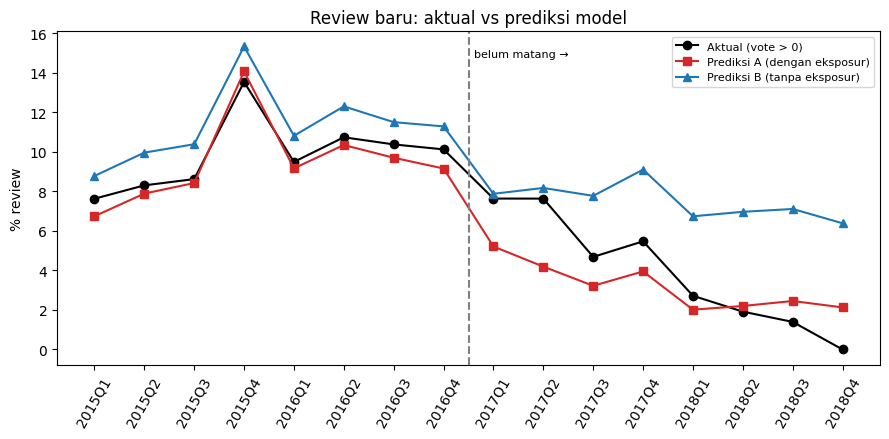

In [25]:
# Model terbaik per skenario berdasarkan PR-AUC VALIDASI (Spark, train penuh)
full = results[(results["engine"] == "Spark MLlib") & (results["train_rows"] == n_train)]
BEST_MODEL = {s: full[full["skenario"] == s].sort_values("val_pr_auc", ascending=False).iloc[0]["model"] for s in SCENARIOS}
THRESHOLD  = {s: PREDICTIONS[(s, BEST_MODEL[s], "Spark MLlib", n_train)][2] for s in SCENARIOS}
print("Model terbaik (validasi):", BEST_MODEL)

recent = (data.filter("split in ('test', 'infer') and tgl >= '2015-01-01'")
              .withColumn("kuartal", F.concat(F.year("tgl").cast("string"), F.lit("Q"), F.quarter("tgl").cast("string"))))

summary = recent.groupBy("kuartal").agg(F.count("*").alias("n"), F.avg("label").alias("helpful_aktual"))
for scenario in SCENARIOS:
    model = MODELS[(scenario, BEST_MODEL[scenario])]
    predicted = (model.transform(recent)
                      .select("kuartal", vector_to_array("probability")[1].alias("p"))
                      .groupBy("kuartal")
                      .agg(F.avg((F.col("p") >= THRESHOLD[scenario]).cast("int")).alias(f"prediksi_{scenario}")))
    summary = summary.join(predicted, "kuartal")

quarterly = summary.orderBy("kuartal").toPandas()
print(quarterly.round(3).to_string(index=False))

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(quarterly["kuartal"], quarterly["helpful_aktual"] * 100, "o-", color="k", label="Aktual (vote > 0)")
ax.plot(quarterly["kuartal"], quarterly["prediksi_A"] * 100, "s-", color="#d62728", label="Prediksi A (dengan eksposur)")
ax.plot(quarterly["kuartal"], quarterly["prediksi_B"] * 100, "^-", color="#1f77b4", label="Prediksi B (tanpa eksposur)")
start = list(quarterly["kuartal"]).index("2017Q1")
ax.axvline(start - 0.5, color="gray", ls="--"); ax.text(start - 0.4, ax.get_ylim()[1] * 0.92, "belum matang →", fontsize=8)
ax.set_ylabel("% review"); ax.set_title("Review baru: aktual vs prediksi model")
plt.xticks(rotation=60); ax.legend(fontsize=8); plt.tight_layout()
plt.savefig(f"{OUT_DIR}/fig_cold_start.png", dpi=150); plt.show()

In [28]:
for scenario in SCENARIOS:
    MODELS[(scenario, BEST_MODEL[scenario])].write().overwrite().save(f"{MODEL_DIR}/{scenario}_{BEST_MODEL[scenario]}")
print("Model terbaik per skenario tersimpan di", MODEL_DIR)

Model terbaik per skenario tersimpan di hdfs://namenode:9000/data/ml/models


In [45]:
print("Daftar model yang ada di dalam dictionary MODELS:")
for key in MODELS.keys():
    print(key)

Daftar model yang ada di dalam dictionary MODELS:
('A', 'LR')
('A', 'RF')
('A', 'GBT')
('B', 'LR')
('B', 'RF')
('B', 'GBT')


In [44]:
MODELS[("B", "LR")].write().overwrite().save(f"{MODEL_DIR}/{scenario}_LR")

In [33]:
!pip install seaborn

Defaulting to user installation because normal site-packages is not writeable
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 294.9/294.9 KB 4.4 MB/s eta 0:00:00a 0:00:01



PROCESSING SCENARIO: A

Skenario A - 10 fitur terpenting (GBT):
text_len               0.337
prod_gap_days          0.163
prod_prev_n            0.107
brand_idx              0.075
tahun                  0.072
abs_rating_dev_past    0.060
overall                0.055
prod_prev_avg          0.029
n_sentences            0.015
digit_ratio            0.015


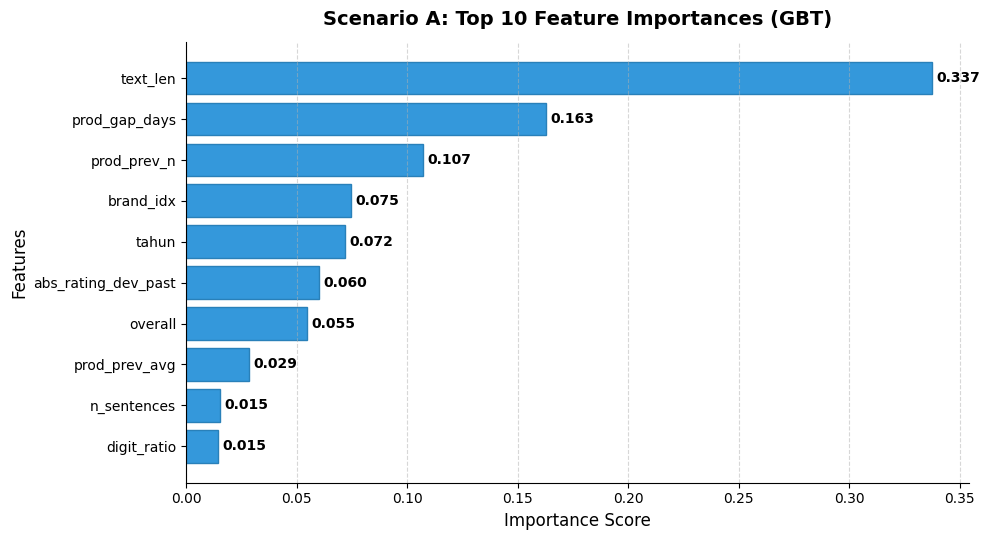


PROCESSING SCENARIO: B

Skenario B - 10 fitur terpenting (GBT):
text_len               0.363
abs_rating_dev_past    0.136
prod_prev_avg          0.127
brand_idx              0.092
verified               0.054
n_sentences            0.040
main_cat_idx           0.033
overall                0.033
user_prev_help         0.033
digit_ratio            0.017


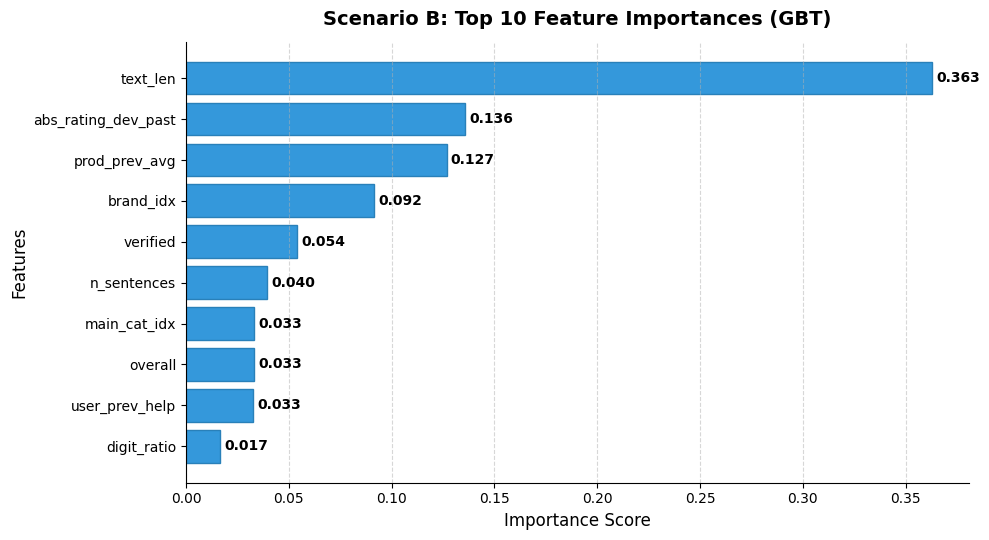

In [35]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from sklearn.metrics import confusion_matrix, classification_report

# 1. LOOP THROUGH YOUR SCENARIOS TO GET PREDICTIONS & FEATURE IMPORTANCE
for scenario, features in SCENARIOS.items():
    print(f"\n==============================")
    print(f"PROCESSING SCENARIO: {scenario}")
    print(f"==============================")
    
    # Define feature names matching your training setup
    names = features + ["price_imp", "brand_idx", "main_cat_idx"]
    
    # Extract GBT Model and feature importances
    gbt_model = MODELS[(scenario, "GBT")]
    importances = gbt_model.stages[-1].featureImportances.toArray()
    
    # Create Series for top 10 features
    importance_series = pd.Series(importances, index=names)
    top_10 = importance_series.sort_values(ascending=False).head(10)
    
    print(f"\nSkenario {scenario} - 10 fitur terpenting (GBT):")
    print(top_10.round(3).to_string())
    
    # -----------------------------------------------------------------
    # A. VISUALIZE TOP 10 FEATURE IMPORTANCES
    # -----------------------------------------------------------------
    fig, ax = plt.subplots(figsize=(10, 5.5))
    df_plot = top_10.sort_values(ascending=True) # Sort ascending for horizontal bar chart layout
    
    bars = ax.barh(df_plot.index, df_plot.values, color='#3498db', edgecolor='#2980b9')
    
    # Add exact numeric values next to the bars
    for bar in bars:
        width = bar.get_width()
        ax.text(width + 0.002, bar.get_y() + bar.get_height()/2, 
                f'{width:.3f}', va='center', ha='left', fontsize=10, fontweight='bold')
        
    ax.set_title(f'Scenario {scenario}: Top 10 Feature Importances (GBT)', fontsize=14, pad=12, fontweight='bold')
    ax.set_xlabel('Importance Score', fontsize=12)
    ax.set_ylabel('Features', fontsize=12)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.grid(axis='x', linestyle='--', alpha=0.5)
    plt.tight_layout()
    plt.show()


CORRELATION HEATMAP: SCENARIO A


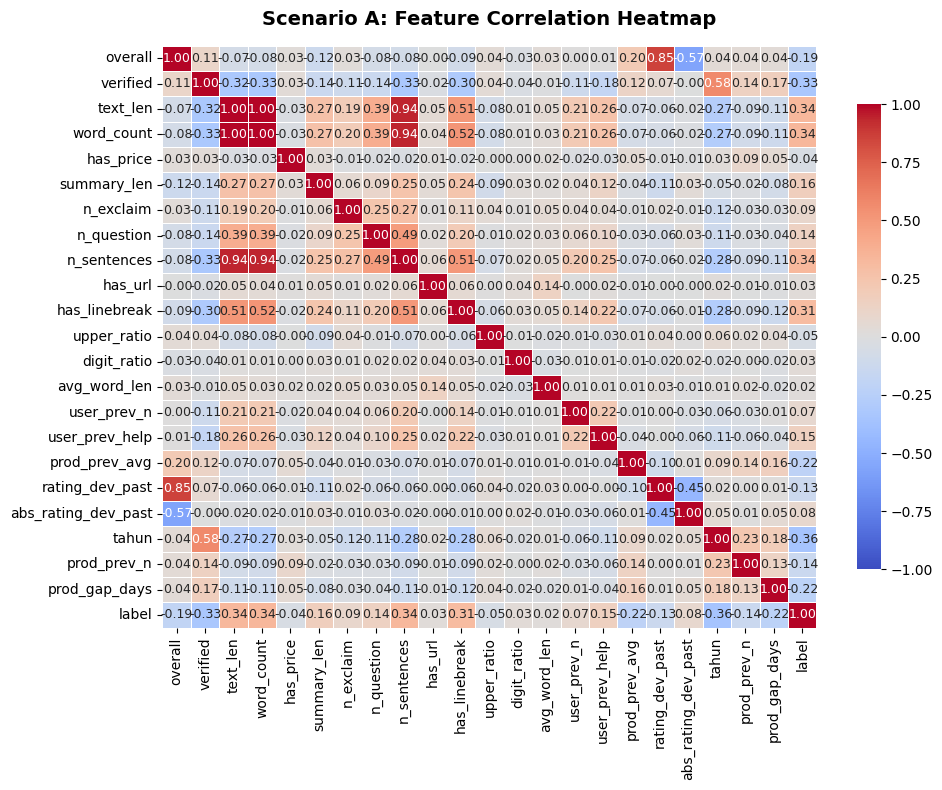


CORRELATION HEATMAP: SCENARIO B


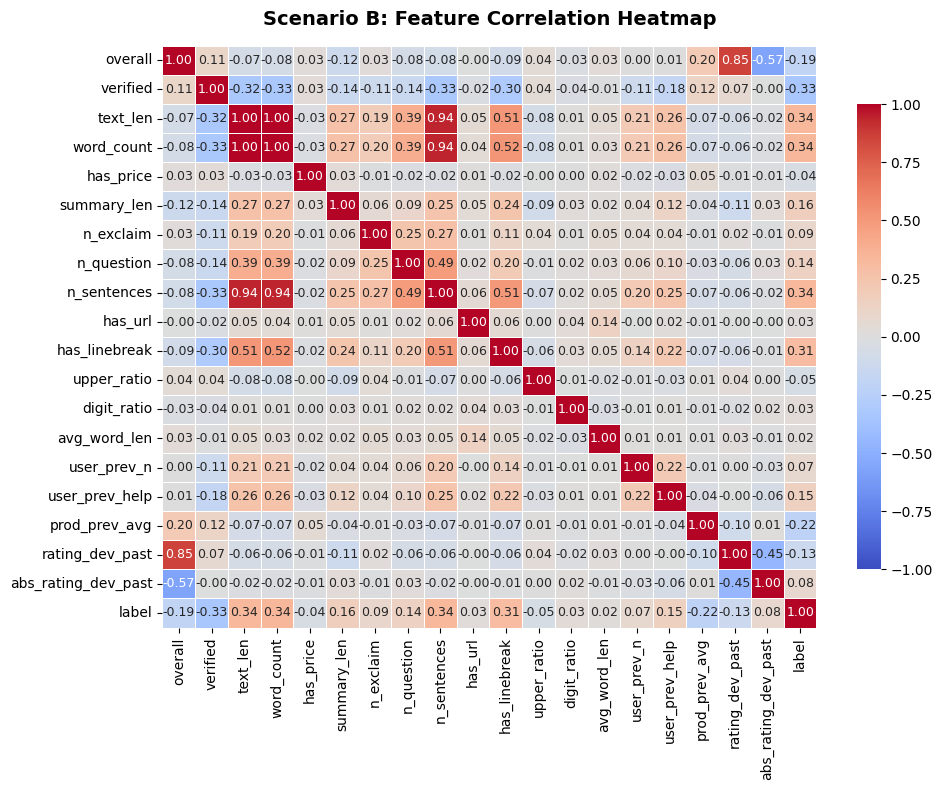

In [40]:
for scenario, features in SCENARIOS.items():
    print(f"\n==============================")
    print(f"CORRELATION HEATMAP: SCENARIO {scenario}")
    print(f"==============================")
    
    all_cols = features + ["price_imp", "brand_idx", "main_cat_idx", "label"]
    
    existing_cols = [col for col in all_cols if col in test_pd.columns]
    df_pd = test.select(existing_cols).toPandas()
    
    corr_matrix = df_pd.corr()
    
    fig, ax = plt.subplots(figsize=(10, 8))
    
    sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, 
                linewidths=0.5, cbar_kws={'shrink': 0.8}, ax=ax, annot_kws={"size": 9})
    
    ax.set_title(f'Scenario {scenario}: Feature Correlation Heatmap', fontsize=14, pad=15, fontweight='bold')
    
    plt.tight_layout()
    plt.show()

In [36]:
RESULTS

[{'accuracy': 0.8183119467551964,
  'precision': 0.5251902040198342,
  'recall': 0.6797250073483785,
  'f1': 0.5925477775009786,
  'pr_auc': 0.5962959990119783,
  'roc_auc': 0.8551604648450566,
  'threshold': 0.6015672579834155,
  'TP': np.int64(41625),
  'FP': np.int64(37632),
  'FN': np.int64(19613),
  'TN': np.int64(216203),
  'skenario': 'A',
  'model': 'LR',
  'engine': 'Spark MLlib',
  'train_rows': 1454487,
  'fit_seconds': 29.3,
  'val_pr_auc': 0.6017910673232103},
 {'accuracy': 0.8323118769301082,
  'precision': 0.554724942696395,
  'recall': 0.6955485156275515,
  'f1': 0.6172059526742114,
  'pr_auc': 0.6511542476722105,
  'roc_auc': 0.8785961301638998,
  'threshold': 0.6544497694492102,
  'TP': np.int64(42594),
  'FP': np.int64(34190),
  'FN': np.int64(18644),
  'TN': np.int64(219645),
  'skenario': 'A',
  'model': 'RF',
  'engine': 'Spark MLlib',
  'train_rows': 1454487,
  'fit_seconds': 127.7,
  'val_pr_auc': 0.6448688683915396},
 {'accuracy': 0.8425380784770513,
  'precisi

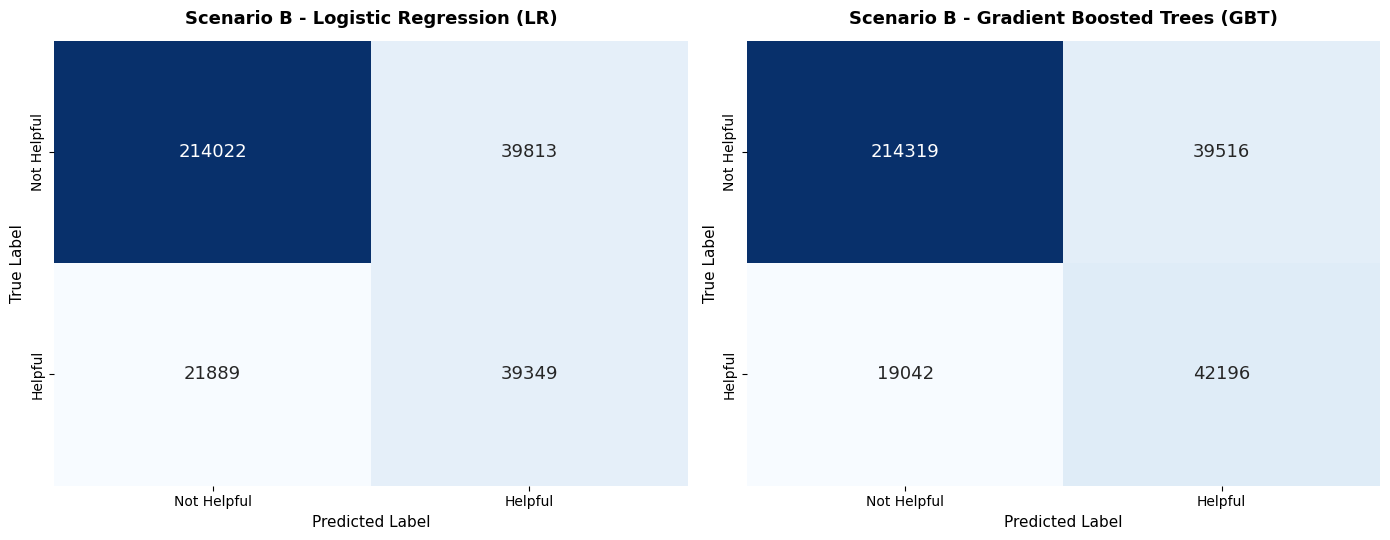

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

def plot_scenario_b_comparison():

    # LR Model
    cm_lr = np.array([
        [214022, 39813],  # [TN, FP]
        [ 21889, 39349]   # [FN, TP]
    ])
    
    # GBT Model
    cm_gbt = np.array([
        [214319, 39516],  # [TN, FP]
        [ 19042, 42196]   # [FN, TP]
    ])
    
    fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
    labels = ['Not Helpful', 'Helpful']
    
    # 1. Logistic Regression (LR) Scenario B
    sns.heatmap(cm_lr, annot=True, fmt='d', cmap='Blues', cbar=False,
                xticklabels=labels, yticklabels=labels, ax=axes[0], annot_kws={"size": 13})
    axes[0].set_title('Scenario B - Logistic Regression (LR)', fontsize=13, pad=12, fontweight='bold')
    axes[0].set_xlabel('Predicted Label', fontsize=11)
    axes[0].set_ylabel('True Label', fontsize=11)
    
    # 2. Gradient Boosted Trees (GBT) Scenario B
    sns.heatmap(cm_gbt, annot=True, fmt='d', cmap='Blues', cbar=False,
                xticklabels=labels, yticklabels=labels, ax=axes[1], annot_kws={"size": 13})
    axes[1].set_title('Scenario B - Gradient Boosted Trees (GBT)', fontsize=13, pad=12, fontweight='bold')
    axes[1].set_xlabel('Predicted Label', fontsize=11)
    axes[1].set_ylabel('True Label', fontsize=11)
    
    plt.tight_layout()
    plt.show()

plot_scenario_b_comparison()

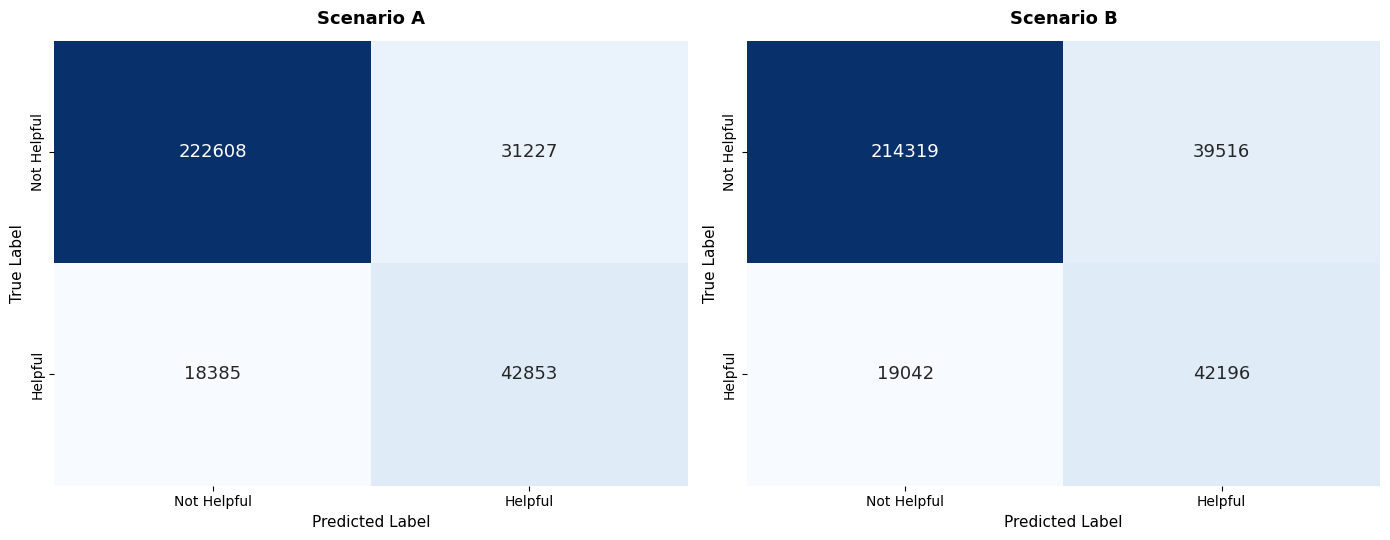

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

def plot_scenario_a_vs_b_comparison():

    # Skenario A 
    cm_a = np.array([
        [222608, 31227],  # [TN, FP]
        [ 18385, 42853]   # [FN, TP]
    ])

    # Skenario B
    cm_b = np.array([
        [214319, 39516],  # [TN, FP]
        [ 19042, 42196]   # [FN, TP]
    ])
    
    fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
    labels = ['Not Helpful', 'Helpful']
    
    # 1. Gradient Boosted Trees (GBT) Scenario A
    sns.heatmap(cm_a, annot=True, fmt='d', cmap='Blues', cbar=False,
                xticklabels=labels, yticklabels=labels, ax=axes[0], annot_kws={"size": 13})
    axes[0].set_title('Scenario A', fontsize=13, pad=12, fontweight='bold')
    axes[0].set_xlabel('Predicted Label', fontsize=11)
    axes[0].set_ylabel('True Label', fontsize=11)
    
    # 2. Gradient Boosted Trees (GBT) Scenario B
    sns.heatmap(cm_b, annot=True, fmt='d', cmap='Blues', cbar=False,
                xticklabels=labels, yticklabels=labels, ax=axes[1], annot_kws={"size": 13})
    axes[1].set_title('Scenario B', fontsize=13, pad=12, fontweight='bold')
    axes[1].set_xlabel('Predicted Label', fontsize=11)
    axes[1].set_ylabel('True Label', fontsize=11)
    
    plt.tight_layout()
    plt.show()

plot_scenario_a_vs_b_comparison()